# Problem Set 1: The Case for a Flat VAT (Ramsey Taxation)

Computational part (Part III) of the problem set. A static economy with a CES household utility over three consumption goods, a CES production frontier that turns labor into private goods and government goods, and a government that must finance fixed purchases G with commodity taxes (a VAT). The notebook builds the household and firm blocks, finds the equilibrium at zero taxes, solves the Ramsey problem numerically, checks whether the optimal VAT is uniform, and explores how the results change with ρ and ψ.

Baseline parameters: N = 3, N_g = 2, w = 1, ω = (0.5, 0.3, 0.2), η = (0.4, 0.4, 0.2), ρ = 0.4, γ = (0.6, 0.4), G = (0.15, 0.10). Note on ψ: the `ψ` used in the code is the reciprocal of the ψ in the problem statement (ψ = 0.6 in the problem corresponds to `ψ = 1/0.6` here), so the production frontier H(y, g) = 1 is concave.

## Question 6A: Household

In [1]:
using Optim, LinearAlgebra, Statistics, Plots, Random
Random.seed!(109)   # the Ramsey solver below uses random starting points

params = (N=3, N_g=2, w=1, ω=(.5,.3,.2), ρ=.4, η=(.4,.4,.2), γ=(.6,.4), ψ=1/0.6, G=(.15,.10))    ##setting the parameters for the entire problem

function utility(c, params)               #utility function: canonical CES (generalized mean) formula
      ω = params.ω
      ρ = params.ρ
      return (sum(ω .^ (1 - ρ) .* c .^ ρ)) ^ (1 / ρ)
end

function household(q, w, params)             #household function which will maximize utility
      ω, ρ, N = params.ω, params.ρ, params.N

    function obj(x)                              #The objective function, taking out one of the c's to make the computation faster,
      c_N = (w - q[1]*x[1] - q[2]*x[2]) / q[3]   #Given the objective x's and q's solves for last c_N, then will return the negative utility
      (any(x .≤ 0) || c_N ≤ 0) && return Inf     #Returns negative utility because optim.jl minimizes, so we need to minimize a negative to find a max
      return -utility([x; c_N], params)
    end
    x0  = fill(w / N, N-1) ./ q[1:N-1]           #This creates an initial guess but by splitting the budget across goods
      res = optimize(obj, x0, NelderMead())      #Runs the Nelder-Mead optimizer to minimize -utility

      c_front = res.minimizer                    #Finds the optimal c1 and c2
      c_star  = [c_front; (w - dot(q[1:N-1], c_front)) / q[N]]   #Finds the optimal c3, and c1,c2
      U_star  = utility(c_star, params)                     #Returns the optimal utility using the optimal consumptions

    return c_star, U_star
  end

  ##Testing it at q = (1, 1, 1)
  q = [1, 1.0, 1.0]
  c_star, U_star = household(q, params.w, params)
  println("c* = ", c_star)
  println("U* = ", U_star)

c* = 

[0.5000468762530847, 0.29996714805359553, 0.19998597569331977]
U* = 0.9999999973072898


The code here is going to maximize utility for the household by choosing three consumptions. In order to make the computations more efficient, rather than finding three consumptions, the computer will only find 2 and the last one will be found from those first two. The objective function takes in values for c1 and c2, then finds c3 from the budget constraint. It will plug in these values into the utility function and return the negative utility. Through the Nelder Mead algorithm, the code will minimize this negative utility by finding the optimal c1, c2, and c3. This can be used to see how the household responds to changes in prices, as those are the parameters for this function.

## Question 6B: Firm

In [2]:
function H(y, g, params)
    η, γ, ψ = collect(params.η), collect(params.γ), params.ψ
    return (sum(η .^ (1-ψ) .* y .^ ψ) + sum(γ .^ (1-ψ) .* g .^ ψ)) ^ (1/ψ)
end

function firm(p, pg, w, params)
    N, N_g = params.N, params.N_g
    η = collect(params.η)
    γ = collect(params.γ)
    ψ = params.ψ
    M = N + N_g

    function mix_obj(x)
        y_tilde = x[1:N]
        g_free  = x[N+1:end]
        (any(y_tilde .≤ 0) || any(g_free .≤ 0)) && return Inf
        g_last = 1.0 - sum(y_tilde) - sum(g_free)
        g_last ≤ 0 && return Inf
        g_tilde = [g_free; g_last]
        R = sum(p[i]  * (y_tilde[i] / η[i]^(1-ψ))^(1/ψ) for i in 1:N) +
            sum(pg[j] * (g_tilde[j] / γ[j]^(1-ψ))^(1/ψ) for j in 1:N_g)
        return -R
    end

    x0   = fill(1.0/M, M-1)
    res1 = optimize(mix_obj, x0, NelderMead(),
                   Optim.Options(iterations=100_000, f_abstol=1e-12, x_abstol=1e-12))

    y_tilde = res1.minimizer[1:N]
    g_free  = res1.minimizer[N+1:end]
    g_last  = 1.0 - sum(y_tilde) - sum(g_free)
    g_tilde = [g_free; g_last]

    # Recover unit-labor outputs from shares
    y_unit = [(y_tilde[i] / η[i]^(1-ψ))^(1/ψ) for i in 1:N]
    g_unit = [(g_tilde[j] / γ[j]^(1-ψ))^(1/ψ) for j in 1:N_g]
    R_unit = dot(p, y_unit) + dot(pg, g_unit)

    # Step 2: Choose the scale L — profit = L*(R_unit - w) is linear in L, so compare the two bounds

    L_low, L_high = 1e-8, 100000
    profit_L(L) = L * (R_unit - w)
    L_star = profit_L(L_high) > profit_L(L_low) ? L_high : L_low

    y_star = L_star .* y_unit
    g_star = L_star .* g_unit

    return y_unit, g_unit, R_unit, L_star, y_star, g_star, g_last, y_tilde, g_tilde
end

p_test  = [0.4, 1.0, 0.8]
pg_test = [0.3, 0.6]
y_unit, g_unit, R_unit, L_star, y_star, g_star, g_last, y_tilde, g_tilde = firm(p_test, pg_test, params.w, params)
profit = dot(p_test, y_star) + dot(pg_test, g_star) - params.w * L_star
println("p         = ", p_test, "  pg = ", pg_test)
println("── Unit bundle (L=1) ────────────────────────────")
println("y_unit    = ", round.(y_unit, digits=6))
println("g_unit    = ", round.(g_unit, digits=6))
println("R_unit    = ", round(R_unit,  digits=6), "  w = ", params.w)
println("── Scale ────────────────────────────────────────")
println("L*        = ", round(L_star,  digits=6))
println("── Scaled output ────────────────────────────────")
println("y*(L)     = ", round.(y_star,  digits=6))
println("g*(L)     = ", round.(g_star,  digits=6))
println("π*        = ", round(profit,   digits=6))
println("g_last= ", g_last)

p         = 

[0.4, 1.0, 0.8]  pg = [0.3, 0.6]
── Unit bundle (L=1) ────────────────────────────
y_unit    = [0.125773, 0.497137, 0.177856]
g_unit    = [0.122539, 0.231007]
R_unit    = 0.865096  w = 1
── Scale ────────────────────────────────────────
L*        = 0.0
── Scaled output ────────────────────────────────
y*(L)     = [0.0, 0.0, 0.0]
g*(L)     = [0.0, 0.0]
π*        = -0.0
g_last= 0.1602018037328369


Now, it is the maximization of the firm. The first thing that happens is the function for the production frontier H, which takes in parameters, as well as y and g as inputs. The firm function will look to maximize revenue with L=1. To do this it will maximize the tilde values, which are each good's share of total production. It leaves one free variable called g_last which is implied to reduce computation. By plugging in the tilde values into the revenue function with given prices, it gives back a -revenue. This negative revenue is minimized using the Nelder Mead algorithm. From the optimal tilde values, the actual y and gs are then recovered. Finally, the R* with L=1 is plugged into a profit function, and since profit is linear in L, the code compares profit at a very small and a very large L to find the optimal value of L. Unless R*=w, L will either go to 0 or to 100,000 which I set as the upper limit to represent L=infinity. With the test prices used here, R* = 0.865 < w = 1, so the firm chooses L* = 0.

## Question 6C: Equilibrium at τ = 0

In [3]:
G_eq = collect(params.G)

function firm_fixed_G(p, params)
    ψ = params.ψ;  η = collect(params.η);  γ = collect(params.γ)
    N = length(η)
    A_G = 1.0 - sum(γ .^ (1 - ψ) .* collect(params.G) .^ ψ)
    A_G ≤ 0 && error("Government purchases exhaust production capacity.")

    function obj(z)
        y_free = exp.(z)
        rem = A_G - sum(η[1:N-1] .^ (1 - ψ) .* y_free .^ ψ)
        rem ≤ 0 && return Inf
        return -sum(p .* [y_free; (rem / η[N]^(1 - ψ))^(1/ψ)])
    end

    z0  = log.([(A_G / (N * η[i]^(1 - ψ)))^(1/ψ) for i in 1:N-1])
    sol = optimize(obj, z0, NelderMead(),
                   Optim.Options(iterations=100_000, f_abstol=1e-12, x_abstol=1e-12))

    y_free = exp.(sol.minimizer)
    rem    = A_G - sum(η[1:N-1] .^ (1 - ψ) .* y_free .^ ψ)
    y_unit = [y_free; (rem / η[N]^(1 - ψ))^(1/ψ)]
    return y_unit, sum(p .* y_unit)
end

function sse(free)
    any(free .≤ 0) && return 1e12
    r_p = [free[1]; free[2]; 1.0]
    y_unit_tr, R_unit_tr = firm_fixed_G(r_p, params)
    R_unit_tr ≤ 0 && return 1e12
    c_tr, _ = household((params.w / R_unit_tr) .* r_p, params.w, params)
    return sum((c_tr .- y_unit_tr) .^ 2)
end

sol_eq = optimize(sse, [1.0, 1.0], NelderMead(),
                  Optim.Options(iterations=100_000, f_abstol=1e-12, x_abstol=1e-12))
sol_eq.minimum > 1e-8 && error("Equilibrium not found (SSE = $(sol_eq.minimum)).")

r_p_sol           = [sol_eq.minimizer[1]; sol_eq.minimizer[2]; 1.0]
y_unit_eq, R_sol  = firm_fixed_G(r_p_sol, params)
p_star            = (params.w / R_sol) .* r_p_sol
c_star_eq, U_star = household(p_star, params.w, params)
H_eq = (sum(collect(params.η) .^ (1 - params.ψ) .* y_unit_eq .^ params.ψ) +
        sum(collect(params.γ) .^ (1 - params.ψ) .* G_eq      .^ params.ψ)) ^ (1/params.ψ)

println("p* (= q*) = ", round.(p_star,    digits=6))
println("c*        = ", round.(c_star_eq, digits=6))
println("y*        = ", round.(y_unit_eq, digits=6))
println("g* = G    = ", round.(G_eq,      digits=6))
println("c* - y*   = ", round.(c_star_eq - y_unit_eq, digits=8), "  (should ≈ 0)")
println("H(y*,G)   = ", round(H_eq,       digits=8),             "  (should = 1.0)")
println("SSE       = ", sol_eq.minimum)
println("U*        = ", round(U_star,      digits=6))

p* (= q*) = 

[1.144368, 0.973924, 1.066411]
c*        = [0.418616, 0.328662, 0.188349]
y*        = [0.418628, 0.328725, 0.188278]
g* = G    = [0.15, 0.1]
c* - y*   = [-1.19e-5, -6.309e-5, 7.038e-5]  (should ≈ 0)
H(y*,G)   = 1.0  (should = 1.0)
SSE       = 9.075025211906729e-9
U*        = 0.931726


The first thing I did was set g as a constant and equal to G. Since the government has no revenue, government prices do not really mean much as there is no government budget to solve so I made the production of government goods constant and altered the budget constraint accordingly. This was after plugging in the gamma and G values. Then, I use this new constraint to maximize private revenue by choosing an allocation of private goods produced. This is the obj(z) which minimizes a negative revenue. Once goods produced is found, I use that allocation as well as an SSE to find private prices by minimizing c*-y* which clears the market. After finding the private prices to minimize (c*-y*)^2 using the firms production and the household function from part A, prices are rescaled to hold the zero-profit condition which is necessary for markets to clear. Finally, after finding the optimal prices, I use that to find the c* and y* of the firm which now should match up. H should also be equal to 1, which means the labor market clears (L = 1).

## Question 6D: Verification

In order to test for accuracy, I made sure first that the answers made economic sense. This often was not the case and I would look to debug. If an answer seemed to be right, I would compare it to my answers from Question 7, the Ramsey allocation which should have the same consumption allocations given a flat tax rate. This was my best way to compare and make sure that my code was consistent. The code also prints the market-clearing residuals c* − y* (which should be close to 0) and checks that H(y*, G) = 1.

## Question 7A: Ramsey Problem

In [4]:
function solve_ramsey_allocation(params)
    G = collect(params.G)
    N = length(params.ω)

    function obj(z)
        C = exp.(z)
        return -utility(C, params) + 1e8 * (H(C, G, params) - 1.0)^2
    end

    best_sol = nothing
    best_val = Inf
    for _ in 1:50
        z0 = log.(rand(N) .* 0.5 .+ 0.1)
        try
            sol = optimize(obj, z0, NelderMead(),
                           Optim.Options(iterations=100_000, f_abstol=1e-12, x_abstol=1e-12))
            if Optim.minimum(sol) < best_val
                best_val = Optim.minimum(sol)
                best_sol = sol
            end
        catch e
            continue
        end
    end
    best_sol === nothing && error("Ramsey allocation optimization failed.")

    C_star = exp.(Optim.minimizer(best_sol))
    return C_star, utility(C_star, params), H(C_star, G, params)
end

C_ram, U_ram, H_ram = solve_ramsey_allocation(params)

println("C*         = ", round.(C_ram, digits=6))
println("U*         = ", round(U_ram,  digits=6))
println("H(C*,G)    = ", round(H_ram,  digits=8), "  (should ≈ 1)")

function implied_q_from_C(C, params)
    q_raw = collect(params.ω) .^ (1 - params.ρ) .* C .^ (params.ρ - 1)
    return params.w .* q_raw ./ dot(q_raw, C)
end

q_ram = implied_q_from_C(C_ram, params)
c_check, _ = household(q_ram, params.w, params)

println("q*         = ", round.(q_ram,                digits=6))
println("c(q*)-C*   = ", round.(c_check .- C_ram,     digits=8))
println("budget     = ", round(dot(q_ram, C_ram),      digits=8), "  (should = w = $(params.w))")

function implied_p_pg_from_allocation(C_target, params)
    η = collect(params.η);  γ = collect(params.γ)
    G = collect(params.G);  ψ = params.ψ;  w = params.w
    H_val  = H(C_target, G, params)
    p_raw  = H_val^(1 - ψ) .* η .^ (1 - ψ) .* C_target .^ (ψ - 1)
    pg_raw = H_val^(1 - ψ) .* γ .^ (1 - ψ) .* G        .^ (ψ - 1)
    total  = dot(p_raw, C_target) + dot(pg_raw, G)
    return w .* p_raw ./ total, w .* pg_raw ./ total
end

p_ram, pg_ram = implied_p_pg_from_allocation(C_ram, params)

println("p*         = ", round.(p_ram,  digits=6))
println("pg*        = ", round.(pg_ram, digits=6))
println("value      = ", round(dot(p_ram, C_ram) + dot(pg_ram, collect(params.G)), digits=8),
        "  (should = w = $(params.w))")

τ_ram = q_ram ./ p_ram .- 1.0   # tax wedge between consumer and producer prices
t_ram = τ_ram .* p_ram;

C*         = 

[0.418643, 0.328722, 0.188266]
U*         = 0.931726
H(C*,G)    = 1.00000001  (should ≈ 1)
q*         = [1.144354, 0.973779, 1.066694]
c(q*)-C*   = 

[1.51e-6, 1.323e-5, -1.37e-5]
budget     = 1.0  (should = w = 1)
p*         = 

[1.030835, 0.877362, 0.960493]
pg*        = [0.39685, 0.39685]
value      = 1.0  (should = w = 1)


The first thing I did was solve the Ramsey problem directly in terms of the allocation C, instead of starting with prices or taxes. Since government goods G are fixed, they enter the resource constraint as a constant part of production that must be accounted for. The function solve_ramsey_allocation(params) chooses the private consumption vector C that maximizes household utility while making sure that the full resource constraint H(C,G)=1 holds, so the objective function minimizes negative utility plus a penalty for being away from the resource constraint. After finding the Ramsey allocation C*, I recover the consumer prices that would make the household choose that allocation using implied_q_from_C(C, params). The idea is that if C* is going to be chosen by the household, then the consumer prices q must line up with the household's marginal utilities. The code then rescales these prices so that the household budget is exactly satisfied, meaning sum(q_i C_i)=w, and I plug those prices back into the household function to check that the household actually chooses C*. Next, I recover the producer prices from the production side using implied_p_pg_from_allocation(C_target, params). These prices come from the marginal resource cost of producing each private good and each government good. This gives both p* for private goods and pg* for government goods, and the prices are then rescaled so that the total value of production equals the wage income, which is the zero-profit/market-clearing normalization. Finally, I compute the tax vector using the wedge between consumer and producer prices, tau_i = q_i/p_i - 1. Since the household spends all of w at prices q and production is worth w at prices p, the VAT revenue sum(t_i C_i) automatically covers government spending sum(pg_j G_j), which the next cell checks.

## Question 7B: Optimal Tax Vector

In [5]:
max_tax_gap = maximum(abs(τ_ram[i] - τ_ram[j]) for i in 1:3 for j in 1:3)
budget_res  = dot(pg_ram, collect(params.G)) - dot(t_ram, C_ram)

println("── Taxes that Implement the Ramsey Allocation ───")
println("τ*         = ", round.(τ_ram, digits = 6))
println("t* = τ·p   = ", round.(t_ram, digits = 6))
println("max|τᵢ-τⱼ| = ", round(max_tax_gap, digits = 10))
println("Gov spend  = ", round(dot(pg_ram, collect(params.G)), digits=8))
println("VAT rev    = ", round(dot(t_ram, C_ram),             digits=8))
println("budget res = ", round(budget_res,                     digits=10))

── Taxes that Implement the Ramsey Allocation ───


τ*         = [0.110124, 0.109895, 0.11057]
t* = τ·p   = [0.113519, 0.096417, 0.106202]
max|τᵢ-τⱼ| = 0.0006752379
Gov spend  = 0.09921256
VAT rev    = 0.09921256
budget res = -0.0


The taxes are uniform up to numerical error: all three rates are about 11%, and max|τᵢ − τⱼ| is below 0.001.

## Question 7C

Yes, the numerical result confirms the case for a flat VAT. The output shows that the optimal tax rates are essentially the same across goods, and max|tau_i - tau_j| is very small. This matches the analytical result from Part II: a flat VAT raises consumer prices by the same proportion, so q_i/q_j = p_i/p_j and relative prices are not distorted. Economically, the government raises revenue without changing the household’s goods mix away from the planner’s allocation. Any small deviation from exact uniformity is most likely from numerical optimization, tolerances, and floating point error rather than a real economic difference.

## Question 8: The Role of ρ and ψ

8A varies ρ ∈ {0.1, 0.3, 0.5, 0.7, 0.9} with ψ held at its baseline. 8B varies ψ over {1.1, 1.3, 1.5, 1.7, 1.9} (in the code's convention, where the baseline is 1/0.6 ≈ 1.67) with ρ = 0.4. For each value the Ramsey allocation is solved numerically and the tax rate is recovered from the price wedges.

── 8a: Vary ρ (ψ=1/0.6 fixed) ──────────────────────────────────
ρ=0.1: c*=[0.4273, 0.3186, 0.188]  τ*=0.110095  max|τᵢ-τⱼ|=0.00041


ρ=0.3: c*=[0.422, 0.3248, 0.1883]  τ*=0.110071  max|τᵢ-τⱼ|=0.00051


ρ=0.5: c*=[0.4146, 0.3332, 0.1885]  τ*=0.110052  max|τᵢ-τⱼ|=0.00064


ρ=0.7: c*=[0.4042, 0.3449, 0.1886]  τ*=0.110083  max|τᵢ-τⱼ|=0.00058


ρ=0.9: c*=[0.3877, 0.3627, 0.1885]  τ*=0.110028  max|τᵢ-τⱼ|=0.00087



── 8b: Vary ψ (ρ=0.4 fixed) ─────────────────────────────────────
ψ=1.1: c*=[0.388, 0.2504, 0.1601]  τ*=0.278293  max|τᵢ-τⱼ|=0.0008


ψ=1.3: c*=[0.405, 0.288, 0.1746]  τ*=0.197464  max|τᵢ-τⱼ|=0.00083


ψ=1.5: c*=[0.4143, 0.3137, 0.1834]  τ*=0.142816  max|τᵢ-τⱼ|=0.00059


ψ=1.7: c*=[0.4192, 0.3311, 0.1892]  τ*=0.104555  max|τᵢ-τⱼ|=0.00099


ψ=1.9: c*=[0.4215, 0.3437, 0.1928]  τ*=0.077285  max|τᵢ-τⱼ|=0.00045


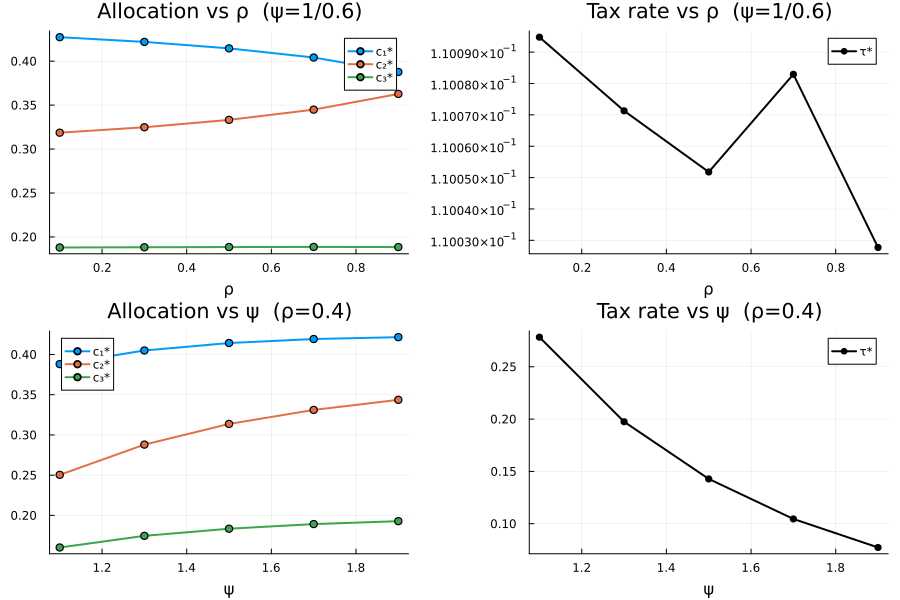

In [6]:
ρ_grid = [0.1, 0.3, 0.5, 0.7, 0.9]
ψ_grid = [1.1, 1.3, 1.5, 1.7, 1.9]

c8a = zeros(5, 3);  τ8a = zeros(5)
c8b = zeros(5, 3);  τ8b = zeros(5)

println("── 8a: Vary ρ (ψ=1/0.6 fixed) ──────────────────────────────────")

for (i, ρ_i) in enumerate(ρ_grid)
    params_i = merge(params, (ρ=ρ_i,))

    c_s, _, _ = solve_ramsey_allocation(params_i)

    q_s = implied_q_from_C(c_s, params_i)
    p_s, pg_s = implied_p_pg_from_allocation(c_s, params_i)

    τ_vec = q_s ./ p_s .- 1.0
    τ_s = mean(τ_vec)

    c8a[i,:] = c_s
    τ8a[i] = τ_s

    println("ρ=$(ρ_i): c*=$(round.(c_s, digits=4))  τ*=$(round(τ_s, digits=6))  max|τᵢ-τⱼ|=$(round(maximum(τ_vec) - minimum(τ_vec), sigdigits=2))")
end

println("\n── 8b: Vary ψ (ρ=0.4 fixed) ─────────────────────────────────────")
for (i, ψ_i) in enumerate(ψ_grid)
    params_i = merge(params, (ψ=ψ_i,))

    c_s, _, _ = solve_ramsey_allocation(params_i)

    q_s = implied_q_from_C(c_s, params_i)
    p_s, pg_s = implied_p_pg_from_allocation(c_s, params_i)

    τ_vec = q_s ./ p_s .- 1.0
    τ_s = mean(τ_vec)

    c8b[i,:] = c_s
    τ8b[i] = τ_s

    println("ψ=$(ψ_i): c*=$(round.(c_s, digits=4))  τ*=$(round(τ_s, digits=6))  max|τᵢ-τⱼ|=$(round(maximum(τ_vec) - minimum(τ_vec), sigdigits=2))")
end

p8a_c = plot(ρ_grid, c8a, label=["c₁*" "c₂*" "c₃*"],
             xlabel="ρ", title="Allocation vs ρ  (ψ=1/0.6)", lw=2, marker=:circle)
p8a_τ = plot(ρ_grid, τ8a, label="τ*", color=:black,
             xlabel="ρ", title="Tax rate vs ρ  (ψ=1/0.6)", lw=2, marker=:circle)
p8b_c = plot(ψ_grid, c8b, label=["c₁*" "c₂*" "c₃*"],
             xlabel="ψ", title="Allocation vs ψ  (ρ=0.4)", lw=2, marker=:circle)
p8b_τ = plot(ψ_grid, τ8b, label="τ*", color=:black,
             xlabel="ψ", title="Tax rate vs ψ  (ρ=0.4)", lw=2, marker=:circle)

plot(p8a_c, p8a_τ, p8b_c, p8b_τ, layout=(2,2), size=(900,600))

The plots and the printed tax gaps show that the optimal VAT stays flat as rho and psi change, but the allocation and required tax rate still move. As rho rises, households are more willing to substitute across goods, so the planner shifts consumption away from C1 and toward C2, while C3 barely changes. The tax rate changes only a little because rho mostly affects the private goods mix rather than the size of government spending. As psi rises, production becomes more flexible, so the economy can produce both government goods and private goods more easily. This is why all private consumption goods rise and the required tax rate falls. Overall, rho and psi affect the allocation and the level of the flat tax, but they do not create a reason for differentiated taxes. As rho gets close to psi, the allocation becomes more sensitive because the ratio formula depends on the gap between the two parameters.